In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

In [2]:
data = fetch_openml("credit-g", version=1, as_frame=True)
df = data.frame
print(df.shape)
df.head()

(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [3]:
df.info()
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass balance:")
print(df['class'].value_counts())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000


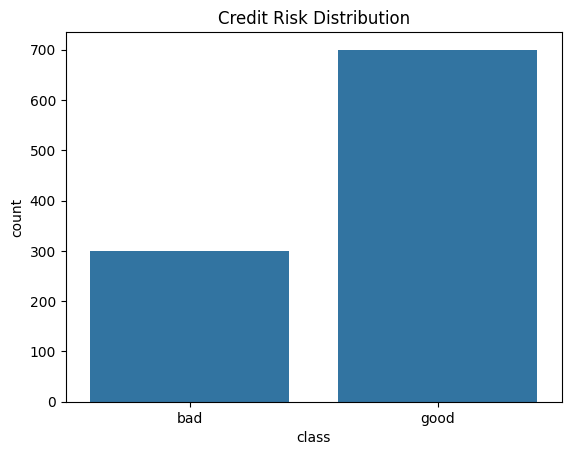

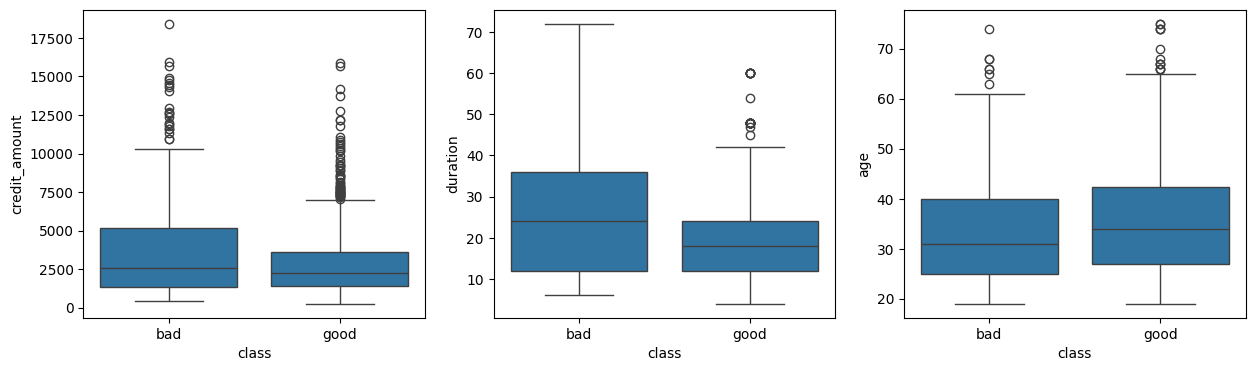

In [4]:
sns.countplot(x='class', data=df)
plt.title("Credit Risk Distribution")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x='class', y='credit_amount', data=df, ax=axes[0])
sns.boxplot(x='class', y='duration', data=df, ax=axes[1])
sns.boxplot(x='class', y='age', data=df, ax=axes[2])
plt.show()

In [5]:
df2 = df.copy()

# New features from financial history
df2['monthly_burden'] = df2['credit_amount'] / df2['duration']
df2['amount_per_age'] = df2['credit_amount'] / df2['age']
df2['burden_vs_income'] = df2['monthly_burden'] * df2['installment_commitment']

# Target: 1 = bad credit, 0 = good credit
y = (df2['class'] == 'bad').astype(int)
X = df2.drop('class', axis=1)

# Convert text columns into numeric columns
X = pd.get_dummies(X, drop_first=True)
print(X.shape)

(1000, 51)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, class_weight='balanced'),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    prob = model.predict_proba(X_test_s)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.750,0.557,0.817,0.662,0.806
Decision Tree,0.645,0.438,0.650,0.523,0.677
Random Forest,0.765,0.686,0.400,0.505,0.794


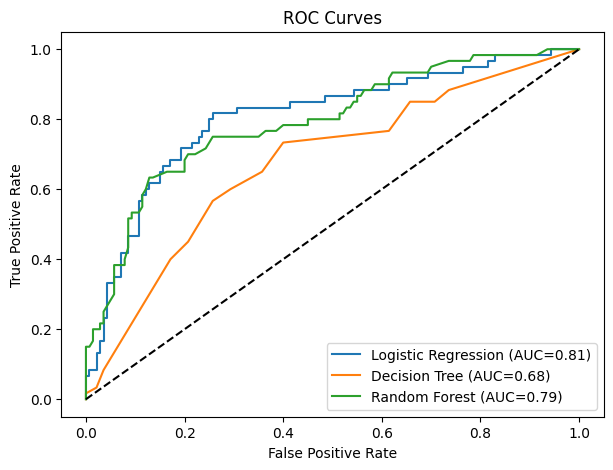

In [8]:
plt.figure(figsize=(7, 5))
for name, model in models.items():
    prob = model.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend()
plt.show()

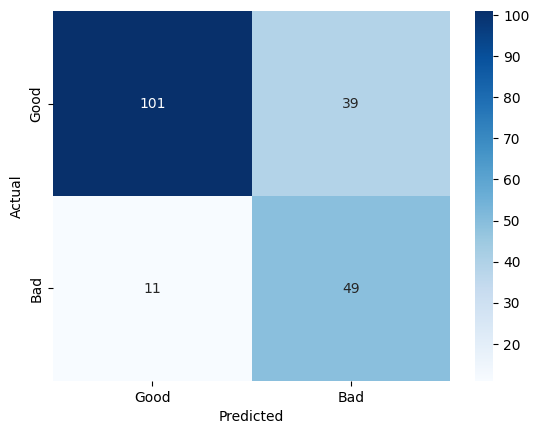

              precision    recall  f1-score   support

        Good       0.90      0.72      0.80       140
         Bad       0.56      0.82      0.66        60

    accuracy                           0.75       200
   macro avg       0.73      0.77      0.73       200
weighted avg       0.80      0.75      0.76       200



In [9]:
best = models["Logistic Regression"]   # change to whichever scored best
cm = confusion_matrix(y_test, best.predict(X_test_s))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Good", "Bad"], yticklabels=["Good", "Bad"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()
print(classification_report(y_test, best.predict(X_test_s), target_names=["Good", "Bad"]))

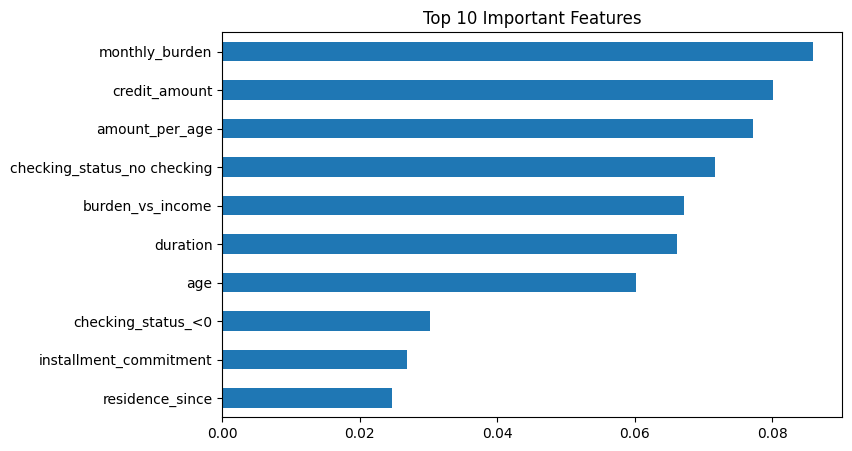

In [10]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot(kind='barh', figsize=(8, 5), title="Top 10 Important Features")
plt.show()

## Conclusion

In this project I built a credit scoring model that predicts whether a
person is a good or bad credit risk, using the German Credit dataset
(1,000 applicants, 20 features). I created three new features
(monthly_burden, amount_per_age, burden_vs_income), encoded the
categorical columns, and trained Logistic Regression, Decision Tree and
Random Forest. Because only 30% of applicants are "bad", I used balanced
class weights.

**Results:** Logistic Regression performed best overall with a Recall of
0.817, F1-Score of 0.662 and ROC-AUC of 0.806. Random Forest had the
highest accuracy (76.5%) and Precision (0.686), but its Recall was only
0.400, meaning it missed most risky borrowers. The Decision Tree
performed worst (64.5% accuracy, ROC-AUC 0.677).

**Why accuracy is misleading here:** The data is imbalanced, so a model
can look accurate while failing on the class that matters. For a lender,
approving a bad borrower (a false negative) usually costs more than
rejecting a good one, so Recall and ROC-AUC are more useful than
accuracy. For this reason I would choose Logistic Regression.

**Important features:** The Random Forest showed that monthly_burden , credit_amount and  amount_per_age contributed most to the prediction.

**Takeaway:** Higher accuracy does not mean a better model. The best
choice depends on the cost of each type of mistake. Future improvements
include hyperparameter tuning, cross-validation, adjusting the decision
threshold to trade Precision against Recall, and testing on a larger
dataset.